# Task 2 – History and calendar features (Maram)
**Input:** `food_clean.csv` (from `Task2_Cleaning.ipynb`, run that first)  
**Output:** `maram_features.csv`, the history and calendar columns, joined with Joud's columns at the end of the week.

In [1]:
import pandas as pd

We only need pandas here.

In [2]:
df = pd.read_csv('food_clean.csv')
df['Inspection Date'] = pd.to_datetime(df['Inspection Date'])
df['First_Seen_Date'] = pd.to_datetime(df['First_Seen_Date'])
print(df.shape)

(126787, 22)


We read the clean file. The date becomes text again when saved to CSV, so we change it back to a real date.

In [3]:
# M1: sort each business's inspections from oldest to newest
df = df.sort_values(by=['Business_ID', 'Inspection Date'])
df[['Business_ID', 'Inspection Date', 'Results']].head(10)

,Business_ID,Inspection Date,Results
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,Pass w/ Conditions
107725,1000049_PEREZ MEXICAN FOOD,2016-01-28,Pass
93348,1000049_PEREZ MEXICAN FOOD,2016-10-11,Fail
93197,1000049_PEREZ MEXICAN FOOD,2016-10-13,Pass
77051,1000049_PEREZ MEXICAN FOOD,2017-08-18,Pass
122910,1000572_JEWEL FOOD STORE #3030,2015-03-26,Fail
122554,1000572_JEWEL FOOD STORE #3030,2015-04-02,Pass
118862,1000572_JEWEL FOOD STORE #3030,2015-06-17,Fail
118411,1000572_JEWEL FOOD STORE #3030,2015-06-25,Pass
117860,1000572_JEWEL FOOD STORE #3030,2015-07-08,Pass


**M1.** We sort by Business_ID and then by date, so the inspections of one business are next to each other, oldest first. The next steps need this order.

In [4]:
# M2: did this business fail its previous inspection?
df['Prev_Fail'] = df.groupby('Business_ID')['Fail'].shift(1)
df[['Business_ID', 'Inspection Date', 'Fail', 'Prev_Fail']].head(10)

,Business_ID,Inspection Date,Fail,Prev_Fail
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,0,NaN
107725,1000049_PEREZ MEXICAN FOOD,2016-01-28,0,0.0
93348,1000049_PEREZ MEXICAN FOOD,2016-10-11,1,0.0
93197,1000049_PEREZ MEXICAN FOOD,2016-10-13,0,1.0
77051,1000049_PEREZ MEXICAN FOOD,2017-08-18,0,0.0
122910,1000572_JEWEL FOOD STORE #3030,2015-03-26,1,NaN
122554,1000572_JEWEL FOOD STORE #3030,2015-04-02,0,1.0
118862,1000572_JEWEL FOOD STORE #3030,2015-06-17,1,0.0
118411,1000572_JEWEL FOOD STORE #3030,2015-06-25,0,1.0
117860,1000572_JEWEL FOOD STORE #3030,2015-07-08,0,0.0


**M2.** `shift(1)` is new for us: it moves the column down by one row, so each inspection gets the result of the inspection before it. `groupby('Business_ID')` makes sure it only looks inside the same business. The first inspection of each business has nothing before it, so it gets an empty value (NaN).

In [5]:
df['First_Inspection'] = df['Prev_Fail'].isnull().apply(lambda x: 1 if x else 0)
df['Prev_Fail'] = df['Prev_Fail'].fillna(0)
df['First_Inspection'].value_counts()

First_Inspection
0    100637
1     26150
Name: count, dtype: int64

We save "is this the first inspection we have for this business?" in its own column (1 = yes), then fill the empty Prev_Fail with 0. This way the model still knows which rows had no history. # of first inspections: 26150

In [6]:
# M3: days since the last inspection of the same business
df['Days_Since_Last'] = df.groupby('Business_ID')['Inspection Date'].diff().dt.days
df['Days_Since_Last'].describe()

count    100637.000000
mean        248.485845
std         237.501085
min           1.000000
25%          12.000000
50%         236.000000
75%         375.000000
max        2564.000000
Name: Days_Since_Last, dtype: float64

**M3.** `diff()` and `.dt.days` are new for us: `diff()` subtracts the previous date from this date (inside the same business), and `.dt.days` turns the result into a number of days. First inspections have no previous date, so they are empty. Median number of days is 236.

In [7]:
median_days = df['Days_Since_Last'].median()
df['Days_Since_Last'] = df['Days_Since_Last'].fillna(median_days)
print(median_days)

236.0


We fill the empty values (first inspections) with the median, because the median is not affected by very long gaps. The First_Inspection column still tells the model these rows were filled.

In [8]:
# M4: month of the inspection
df['Month'] = df['Inspection Date'].dt.month
df['Month'].value_counts().sort_index()

Month
1     10333
2      9216
3     11701
4     10818
5     11599
6     11984
7      9396
8     11002
9     11054
10    11212
11     9822
12     8650
Name: count, dtype: int64

**M4.** The month (1–12). Hot months may have more temperature problems; the Chicago model also used temperature.

In [9]:
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

df['Season'] = df['Month'].apply(get_season)
df['Season'].value_counts()

Season
Spring    34118
Summer    32382
Fall      32088
Winter    28199
Name: count, dtype: int64

We group the months into seasons with a def + apply, like we did in the labs.

In [10]:
# M5: keep the 8 most common facility types, the rest becomes 'Other'
top8 = df['Facility Type'].value_counts().head(8).index
top8

Index(['Restaurant', 'Grocery Store', 'School', 'Children's Services Facility',
       'Daycare Above and Under 2 Years', 'Bakery', 'Long Term Care',
       'Daycare (2 - 6 Years)'],
      dtype='str', name='Facility Type')

**M5.** There are many facility types and most have very few rows. We keep the 8 most common ones (written above).

In [11]:
def group_facility(t):
    if t in top8:
        return t
    else:
        return 'Other'

df['Facility_Group'] = df['Facility Type'].apply(group_facility)
df['Facility_Group'].value_counts()

Facility_Group
Restaurant                         87530
Grocery Store                      14408
School                              8822
Other                               6054
Children's Services Facility        3915
Daycare Above and Under 2 Years     1898
Bakery                              1839
Long Term Care                      1225
Daycare (2 - 6 Years)               1096
Name: count, dtype: int64

Every other type becomes "Other", the same idea as grouping small categories in the Kindle assignment. Later, for the model, we will turn this column into numbers with `get_dummies`.

In [12]:
# M6: risk as a number
def risk_number(r):
    if r == 'Risk 1 (High)':
        return 1
    elif r == 'Risk 2 (Medium)':
        return 2
    elif r == 'Risk 3 (Low)':
        return 3
    else:
        return 0

df['Risk_Num'] = df['Risk'].apply(risk_number)
df['Risk_Num'].value_counts()

Risk_Num
1    98246
2    21563
3     6977
0        1
Name: count, dtype: int64

**M6.** The model needs numbers, so Risk 1 (High) = 1, Risk 2 = 2, Risk 3 (Low) = 3, and Unknown = 0.

In [13]:
# M7: placebo period: a fake change date (1 Jan 2017) inside the old-code years
def placebo_period(date):
    if date < pd.Timestamp('2017-01-01'):
        return 'Before 2017'
    else:
        return 'After 2017'

df['Placebo_Period'] = df['Inspection Date'].apply(placebo_period)
df['Placebo_Period'].value_counts()

Placebo_Period
After 2017     89195
Before 2017    37592
Name: count, dtype: int64

**M7.** For H3 we compare the real change (July 2018) with a fake one (January 2017), when nothing changed. If the model drops much more at 2018 than at 2017, the drop is caused by the new code. (Period with the grace period is already made in the cleaning notebook.)

In [14]:
# M8: Past_Fail_Rate, M9: Num_Past_Inspections
num_past = df.groupby('Business_ID').cumcount()
df['Past_Fail_Rate'] = ((df.groupby('Business_ID')['Fail'].cumsum() - df['Fail']) / num_past).fillna(0)
df['Num_Past_Inspections'] = num_past
df[['Business_ID', 'Inspection Date', 'Fail', 'Prev_Fail', 'Num_Past_Inspections', 'Past_Fail_Rate']].head(10)

,Business_ID,Inspection Date,Fail,Prev_Fail,Num_Past_Inspections,Past_Fail_Rate
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,0,0.0,0,0.000000
107725,1000049_PEREZ MEXICAN FOOD,2016-01-28,0,0.0,1,0.000000
93348,1000049_PEREZ MEXICAN FOOD,2016-10-11,1,0.0,2,0.000000
93197,1000049_PEREZ MEXICAN FOOD,2016-10-13,0,1.0,3,0.333333
77051,1000049_PEREZ MEXICAN FOOD,2017-08-18,0,0.0,4,0.250000
122910,1000572_JEWEL FOOD STORE #3030,2015-03-26,1,0.0,0,0.000000
122554,1000572_JEWEL FOOD STORE #3030,2015-04-02,0,1.0,1,1.000000
118862,1000572_JEWEL FOOD STORE #3030,2015-06-17,1,0.0,2,0.500000
118411,1000572_JEWEL FOOD STORE #3030,2015-06-25,0,1.0,3,0.666667
117860,1000572_JEWEL FOOD STORE #3030,2015-07-08,0,0.0,4,0.500000


**M8.** `Past_Fail_Rate` is the share of the earlier visits of the business that had a fail.

**M9.** `Num_Past_Inspections` keeps the count of earlier visits.

In [15]:
# M10: Days_Since_First_Seen
df['Days_Since_First_Seen'] = (df['Inspection Date'] - df['First_Seen_Date']).dt.days
df['Days_Since_First_Seen'].describe()

count    126787.000000
mean       1649.380749
std        1267.005468
min           0.000000
25%         478.000000
50%        1636.000000
75%        2541.000000
max        4740.000000
Name: Days_Since_First_Seen, dtype: float64

**M10.** `Days_Since_First_Seen` is the assumed age of the facility. It is calculated from the date of first seen till the date of the inspection. We assume that the age of the facility is 0 on its first inspection date (first seen date).<br>Note that businesses older than 2010 looks as if they started in 2010 because the data starts in 2010.

In [16]:
df['Inspection Type'].unique()

<StringArray>
[                               'Canvass',
                  'Canvass Re-Inspection',
                              'Complaint',
                'Complaint Re-Inspection',
                   'Short Form Complaint',
                           'Consultation',
                                'License',
               'Suspected Food Poisoning',
                      'Recent Inspection',
 'Suspected Food Poisoning Re-inspection',
           'Complaint-Fire Re-inspection',
                      'Recent inspection',
                         'Non-Inspection',
                  'License Re-Inspection',
             'Special Events (Festivals)',
                            'Tag Removal',
                        'COVID COMPLAINT',
                               'NO ENTRY']
Length: 18, dtype: str

Check for the different inspection types present and how re-inspections are marked. Note that mostly it is written as Re-Inspection and once as Re-inspection. So, the criteria (regex) on which the inspection type is considered as re-inspection should be flexible to appeal different writing styles.

In [17]:
# M11: Is_Reinspection
df['Is_Reinspection'] = df['Inspection Type'].str.contains(r're-?insp', case=False, na=False)
df[['Business_ID','Inspection Date','Inspection Type','Is_Reinspection']].head(10)

,Business_ID,Inspection Date,Inspection Type,Is_Reinspection
123528,1000049_PEREZ MEXICAN FOOD,2015-03-13,Canvass,False
107725,1000049_PEREZ MEXICAN FOOD,2016-01-28,Canvass,False
93348,1000049_PEREZ MEXICAN FOOD,2016-10-11,Canvass,False
93197,1000049_PEREZ MEXICAN FOOD,2016-10-13,Canvass Re-Inspection,True
77051,1000049_PEREZ MEXICAN FOOD,2017-08-18,Canvass,False
122910,1000572_JEWEL FOOD STORE #3030,2015-03-26,Complaint,False
122554,1000572_JEWEL FOOD STORE #3030,2015-04-02,Complaint Re-Inspection,True
118862,1000572_JEWEL FOOD STORE #3030,2015-06-17,Complaint,False
118411,1000572_JEWEL FOOD STORE #3030,2015-06-25,Complaint Re-Inspection,True
117860,1000572_JEWEL FOOD STORE #3030,2015-07-08,Short Form Complaint,False


**M11.** `Is_Reinspection` checks if the `Inspection Type` contains "Re-Inspection" in different formats with or without -, uppercase or lowercase and if the value of `Inspection Type` is NaN it sets `Is_Reinspection` to False

In [18]:
# Check: Prev_Fail against this result
pd.crosstab(df['Prev_Fail'], df['Fail'], normalize='index').round(3)

Fail,0,1
Prev_Fail,,
0.0,0.743,0.257
1.0,0.895,0.105


Quick check: if businesses that failed last time fail more often this time, Prev_Fail is a useful feature. This crosstab shows that the facilities who failed before are less likely to fail again than those who passed before, (Fail = 1 and Prev_Fail = 1) => 10.5% while (Fail = 1 and Prev_Fail = 0) => 25.7%.<br>This may be due to the results of re-inspections (usually facilities may pass on re-inspections)

In [19]:
# Check: Prev_Fail against this result, re-inspections not included
pd.crosstab(df.loc[~df['Is_Reinspection'], 'Prev_Fail'], df.loc[~df['Is_Reinspection'], 'Fail'], normalize='index').round(3)

Fail,0,1
Prev_Fail,,
0.0,0.738,0.262
1.0,0.668,0.332


This check supports our assumption that re-inspections affects the Fail = 1 given that Prev_Fail = 1 case. Now the facilities that failed before are more likely to fail again than those who passed before, (Fail = 1 and Prev_Fail = 1) => 33.2% while (Fail = 1 and Prev_Fail = 0) => 26.2%.<br>This aligns with the findings of one of the research papers.

In [20]:
cols = ['Inspection ID', 'Prev_Fail', 'First_Inspection', 'Days_Since_Last',
        'Month', 'Season', 'Facility_Group', 'Risk_Num', 'Placebo_Period', 'Past_Fail_Rate', 'Num_Past_Inspections', 'Days_Since_First_Seen', 'Is_Reinspection']
df[cols].to_csv('maram_features.csv', index=False)
print(df[cols].shape)

(126787, 13)


We save only the ID and the new columns. At the end of the week this file is joined with Joud's file and the clean file on `Inspection ID`.

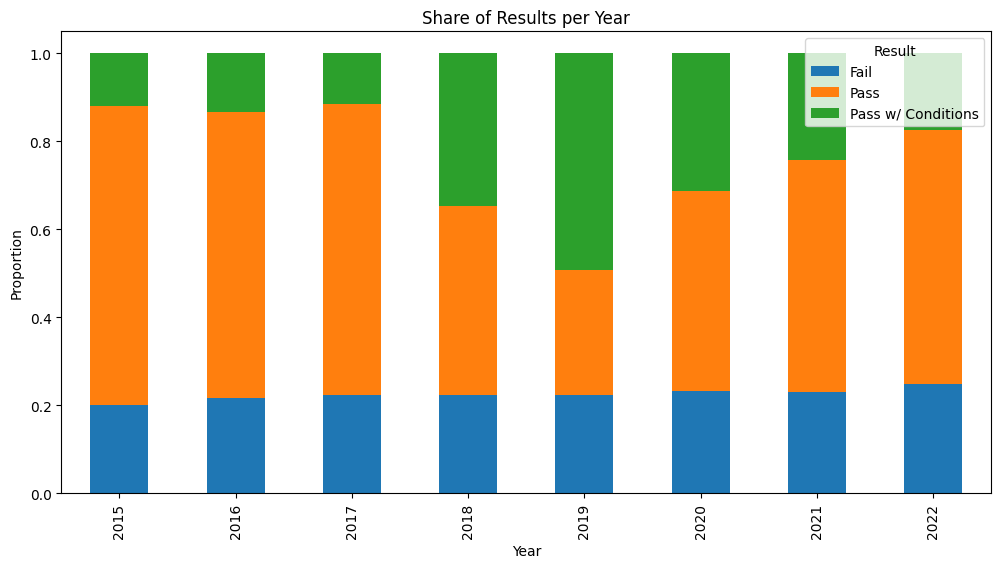

In [21]:
# share of each result in each year (each row adds up to 1)
import matplotlib.pyplot as plt
ct = pd.crosstab(df['Inspection Date'].dt.year, df['Results'])
year_share = ct.divide(ct.sum(axis='columns'), axis='rows')
year_share.plot.bar(stacked=True, figsize=(12, 6))
plt.title('Share of Results per Year')
plt.xlabel('Year')
plt.ylabel('Proportion')
plt.legend(title='Result')
plt.show()

This stacked bar plot supports the hypothesis that the change in violations affected how the inspections are handled. The fail rate stays about the same every year, but the share of Pass and Pass W/ Conditions changes a lot in 2018-2019, so it seems that the change mainly affected how facilities pass, not how often they fail.